<a href="https://colab.research.google.com/github/denizbutengineer/bart-capacity-planner/blob/main/btk_final_proje.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install -q xgboost lightgbm shap joblib

import os
import json
import warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import files

from sklearn.model_selection import train_test_split, TimeSeriesSplit, cross_validate, RandomizedSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, RobustScaler
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import shap

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="viridis")
print("Kütüphaneler başarıyla yüklendi!")

Kütüphaneler başarıyla yüklendi!


In [2]:
file_path = "date-hour-soo-dest-2025.csv" if os.path.exists("date-hour-soo-dest-2025.csv") else "date-hour-soo-dest-2025.zip"

# 1. satırdaki rapor üst bilgisini atlayarak (skiprows=1) 5 sütunlu gerçek veriyi oku
preview = pd.read_csv(file_path, skiprows=1, nrows=5, header=None)
first_val = str(preview.iloc[0, 1]).strip()

if first_val.isdigit():
    raw_df = pd.read_csv(file_path, skiprows=1, header=None, names=['Date', 'Hour', 'Origin', 'Destination', 'Trip_Count'])
else:
    raw_df = pd.read_csv(file_path, skiprows=1)
    raw_df.columns = ['Date', 'Hour', 'Origin', 'Destination', 'Trip_Count']

print(f"Ham Veri Boyutu (OD Matrisi): {raw_df.shape}")

# İstasyon + Tarih + Saat bazlı toplam giriş yolcusuna indirgeme
df = raw_df.groupby(['Date', 'Hour', 'Origin'], as_index=False)['Trip_Count'].sum()
df.rename(columns={'Trip_Count': 'Passenger_Count'}, inplace=True)
del raw_df

print(f"Toplulaştırılmış Veri Boyutu (İstasyon-Saat): {df.shape}")
display(df.head())

Ham Veri Boyutu (OD Matrisi): (9143256, 5)
Toplulaştırılmış Veri Boyutu (İstasyon-Saat): (381657, 4)


,Date,Hour,Origin,Passenger_Count
0,2025-01-01,0,12TH,30
1,2025-01-01,0,16TH,75
2,2025-01-01,0,19TH,61
3,2025-01-01,0,24TH,67
4,2025-01-01,0,ANTC,1


In [3]:
print("--- Veri Kalitesi Kontrolleri ---")
print("Eksik Değerler:\n", df.isna().sum())
print("Mükerrer Kayıt Sayısı:", df.duplicated().sum())
print("Negatif/Sıfır Yolcu Sayısı:", (df['Passenger_Count'] <= 0).sum())

# Kronolojik sıralama (Data Leakage önlemek için zorunlu)
df['Date'] = pd.to_datetime(df['Date'])
df = df.sort_values(['Date', 'Hour', 'Origin']).reset_index(drop=True)

# BART gece 01:00 - 04:00 arası bakım nedeniyle kapalıdır; aktif işletme saatlerini (05:00 - 23:00) filtrele
df = df[df['Hour'].between(5, 23)].reset_index(drop=True)
print(f"Aktif İşletme Saatleri Sonrası Veri Boyutu: {df.shape}")
display(df.describe().T)

--- Veri Kalitesi Kontrolleri ---
Eksik Değerler:
 Date               0
Hour               0
Origin             0
Passenger_Count    0
dtype: int64
Mükerrer Kayıt Sayısı: 0
Negatif/Sıfır Yolcu Sayısı: 0
Aktif İşletme Saatleri Sonrası Veri Boyutu: (337876, 4)


,count,mean,min,25%,50%,75%,max,std
Date,337876,2025-07-01 16:31:07.317004032,2025-01-01 00:00:00,2025-04-01 00:00:00,2025-07-02 00:00:00,2025-10-01 00:00:00,2025-12-31 00:00:00,NaN
Hour,337876.0,14.208861,5.0,10.0,14.0,19.0,23.0,5.381071
Passenger_Count,337876.0,159.491876,1.0,41.0,88.0,183.0,5028.0,261.102984


In [4]:
def add_bart_features(data):
    d = data.copy()
    # BART Çift Tepeli (Bimodal) İşe Gidiş-Geliş Pik Saatleri (07-09 ve 16-19)
    d['Is_Commute_Peak'] = ((d['Hour'].between(7, 9)) | (d['Hour'].between(16, 19))).astype(int)

    # Döngüsel Saat Kodlaması (Cyclical Encoding)
    d['Hour_Sin'] = np.sin(2 * np.pi * d['Hour'] / 24.0)
    d['Hour_Cos'] = np.cos(2 * np.pi * d['Hour'] / 24.0)

    # BART Kritik Koridor ve Havalimanı İstasyon Bayrakları
    transbay_core = {'EMBR', 'MONT', 'POWL', 'CIVC', 'WOAK', '12TH', '19TH'}
    airport_stations = {'SFIA', 'OAKL', 'MLBR'}
    d['Is_Transbay_Core'] = d['Origin'].isin(transbay_core).astype(int)
    d['Is_Airport'] = d['Origin'].isin(airport_stations).astype(int)
    return d

df = add_bart_features(df)
print("Evrensel özellikler eklendi:", list(df.columns))
display(df.head())

Evrensel özellikler eklendi: ['Date', 'Hour', 'Origin', 'Passenger_Count', 'Is_Commute_Peak', 'Hour_Sin', 'Hour_Cos', 'Is_Transbay_Core', 'Is_Airport']


,Date,Hour,Origin,Passenger_Count,Is_Commute_Peak,Hour_Sin,Hour_Cos,Is_Transbay_Core,Is_Airport
0,2025-01-01,5,24TH,1,0,0.965926,2.588190e-01,0,0
1,2025-01-01,5,ROCK,1,0,0.965926,2.588190e-01,0,0
2,2025-01-01,6,12TH,1,0,1.000000,6.123234e-17,1,0
3,2025-01-01,6,BALB,1,0,1.000000,6.123234e-17,0,0
4,2025-01-01,6,CIVC,2,0,1.000000,6.123234e-17,1,0


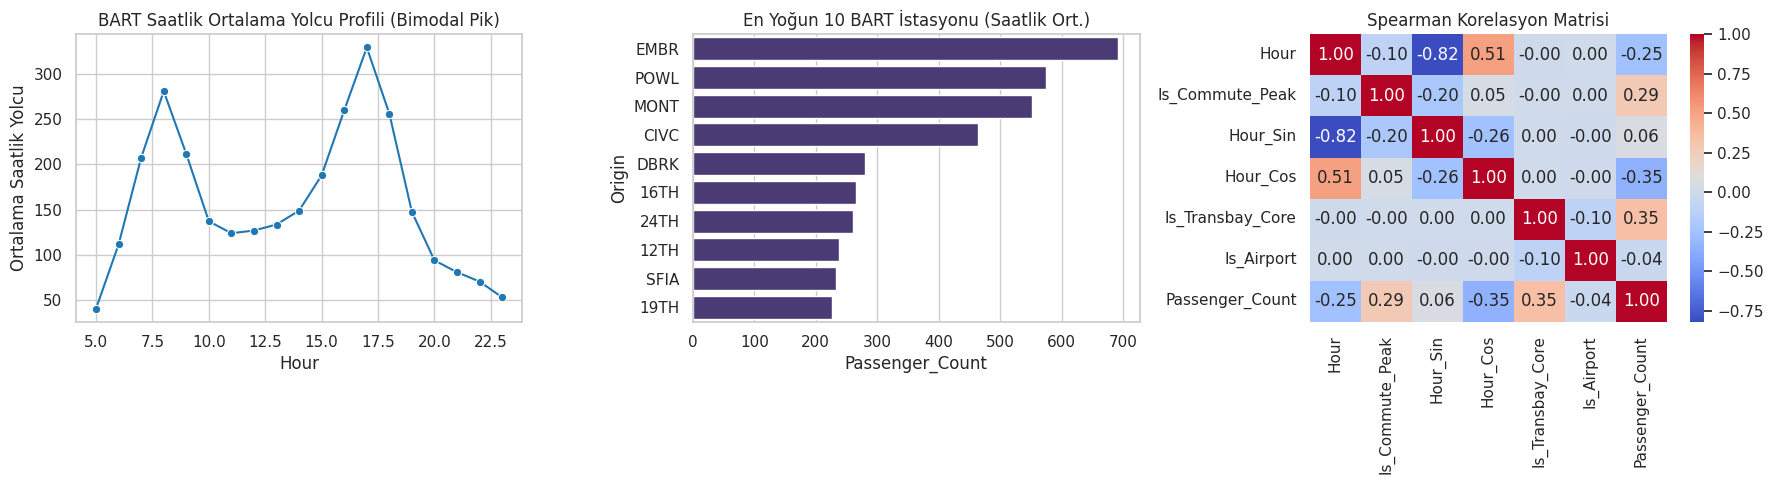

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Grafik 1: Saatlik Ortalama Yolcu Profili
hourly_profile = df.groupby('Hour')['Passenger_Count'].mean().reset_index()
sns.lineplot(data=hourly_profile, x='Hour', y='Passenger_Count', marker='o', color='#1f77b4', ax=axes[0])
axes[0].set_title("BART Saatlik Ortalama Yolcu Profili (Bimodal Pik)")
axes[0].set_ylabel("Ortalama Saatlik Yolcu")

# Grafik 2: En Yoğun 10 BART İstasyonu
top_stations = df.groupby('Origin')['Passenger_Count'].mean().nlargest(10).reset_index()
sns.barplot(data=top_stations, x='Passenger_Count', y='Origin', ax=axes[1])
axes[1].set_title("En Yoğun 10 BART İstasyonu (Saatlik Ort.)")

# Grafik 3: Spearman Korelasyon Matrisi
num_cols_eda = ['Hour', 'Is_Commute_Peak', 'Hour_Sin', 'Hour_Cos', 'Is_Transbay_Core', 'Is_Airport', 'Passenger_Count']
sns.heatmap(df[num_cols_eda].corr(method='spearman'), annot=True, fmt=".2f", cmap="coolwarm", ax=axes[2])
axes[2].set_title("Spearman Korelasyon Matrisi")

plt.tight_layout()
plt.savefig("bart_eda_grafikleri.png", dpi=150)
plt.show()

In [6]:
feature_cols = ['Origin', 'Hour', 'Is_Commute_Peak', 'Hour_Sin', 'Hour_Cos', 'Is_Transbay_Core', 'Is_Airport']
target_col = 'Passenger_Count'

X = df[feature_cols]
y = df[target_col]

# Zamansal sırayı bozmadan %80 Eğitim, %20 Hold-Out Test ayırımı (shuffle=False)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, shuffle=False)
print(f"Train Seti: {X_train.shape}, Test Seti: {X_test.shape}")

cat_features = ['Origin']
num_features = ['Hour', 'Is_Commute_Peak', 'Hour_Sin', 'Hour_Cos', 'Is_Transbay_Core', 'Is_Airport']

preprocessor = ColumnTransformer(
    transformers=[
        ('num', Pipeline([
            ('imputer', SimpleImputer(strategy='median')),
            ('scaler', RobustScaler())
        ]), num_features),
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cat_features)
    ]
)
print("Sızıntısız ColumnTransformer Pipeline hazırlandı.")

Train Seti: (270300, 7), Test Seti: (67576, 7)
Sızıntısız ColumnTransformer Pipeline hazırlandı.


In [7]:
tscv = TimeSeriesSplit(n_splits=3)

models = {
    "1. Dummy Baseline (Mean)": DummyRegressor(strategy="mean"),
    "2. Linear Regression": LinearRegression(),
    "3. Ridge Regression": Ridge(alpha=1.0),
    "4. Decision Tree": DecisionTreeRegressor(max_depth=12, random_state=42),
    "5. Random Forest": RandomForestRegressor(n_estimators=60, max_depth=14, n_jobs=-1, random_state=42),
    "6. LightGBM": LGBMRegressor(n_estimators=150, learning_rate=0.1, random_state=42, verbose=-1),
    "7. XGBoost": XGBRegressor(n_estimators=150, learning_rate=0.1, max_depth=8, n_jobs=-1, random_state=42)
}

results = []
for name, model in models.items():
    pipe = Pipeline([('prep', preprocessor), ('model', model)])
    cv_res = cross_validate(
        pipe, X_train, y_train, cv=tscv,
        scoring=['neg_mean_absolute_error', 'neg_root_mean_squared_error', 'r2'],
        n_jobs=-1
    )
    results.append({
        "Model": name,
        "CV_MAE": -cv_res['test_neg_mean_absolute_error'].mean(),
        "CV_RMSE": -cv_res['test_neg_root_mean_squared_error'].mean(),
        "CV_R2": cv_res['test_r2'].mean()
    })

results_df = pd.DataFrame(results).sort_values("CV_RMSE")
print("--- Model Karşılaştırma Tablosu (TimeSeriesSplit CV) ---")
display(results_df)

--- Model Karşılaştırma Tablosu (TimeSeriesSplit CV) ---


,Model,CV_MAE,CV_RMSE,CV_R2
6,7. XGBoost,54.899218,135.866674,0.748106
5,6. LightGBM,55.066901,135.890636,0.748017
4,5. Random Forest,63.104325,139.916307,0.732872
3,4. Decision Tree,64.929503,141.266868,0.727683
1,2. Linear Regression,100.290421,215.469526,0.366651
2,3. Ridge Regression,100.285519,215.470999,0.366642
0,1. Dummy Baseline (Mean),135.601943,270.919294,-0.001269


In [8]:
# Aday Model (XGBoost) için RandomizedSearchCV Optimizasyonu
xgb_pipe = Pipeline([('prep', preprocessor), ('model', XGBRegressor(n_jobs=-1, random_state=42))])
param_dist = {
    'model__n_estimators': [150, 250],
    'model__max_depth': [6, 8, 10],
    'model__learning_rate': [0.05, 0.08, 0.1],
    'model__subsample': [0.8, 1.0]
}

search = RandomizedSearchCV(
    xgb_pipe, param_distributions=param_dist, n_iter=6, cv=tscv,
    scoring='neg_root_mean_squared_error', n_jobs=-1, random_state=42
)
search.fit(X_train, y_train)
best_xgb = search.best_estimator_
print("En İyi XGBoost Parametreleri:", search.best_params_)

# Güçlü Rakip: Ayarlanmış LightGBM
best_lgbm = Pipeline([
    ('prep', preprocessor),
    ('model', LGBMRegressor(n_estimators=250, max_depth=10, learning_rate=0.08, num_leaves=31, random_state=42, verbose=-1))
])
best_lgbm.fit(X_train, y_train)
print("Rakip LightGBM eğitimi tamamlandı.")

En İyi XGBoost Parametreleri: {'model__subsample': 1.0, 'model__n_estimators': 250, 'model__max_depth': 10, 'model__learning_rate': 0.1}
Rakip LightGBM eğitimi tamamlandı.


--- FİNAL HOLD-OUT TEST SONUÇLARI ---


,Model,Test_MAE,Test_RMSE,Test_R2
1,Tuned LightGBM,56.459943,137.191215,0.659409
0,Tuned XGBoost,56.030426,137.317101,0.658784


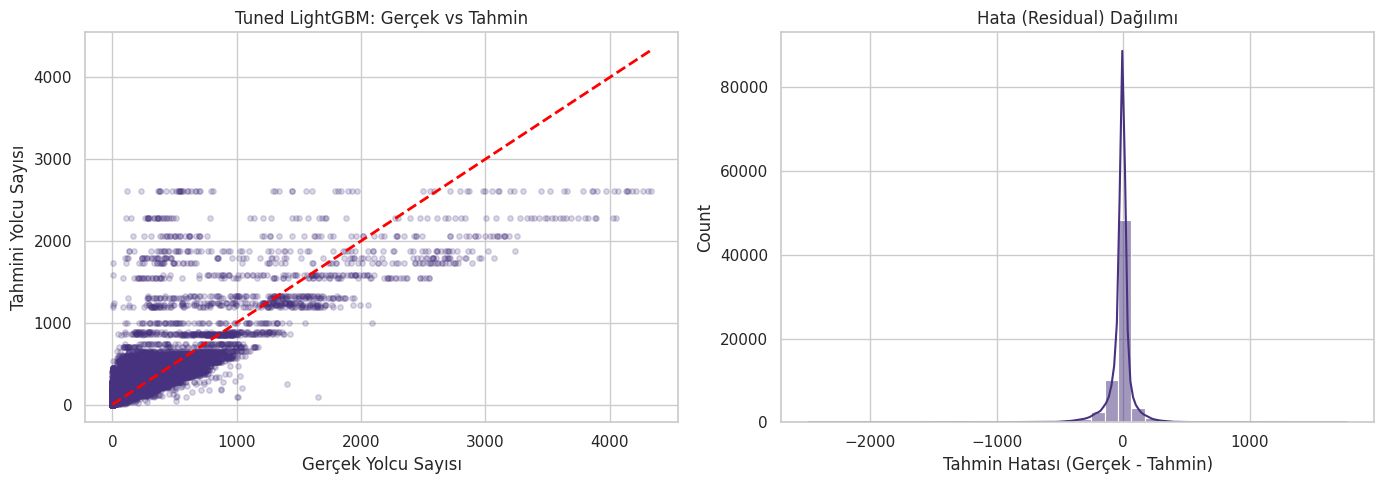

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [10]:
final_candidates = {"Tuned XGBoost": best_xgb, "Tuned LightGBM": best_lgbm}
test_summary = []

for name, pipe in final_candidates.items():
    preds = np.clip(pipe.predict(X_test), 0, None)
    test_summary.append({
        "Model": name,
        "Test_MAE": mean_absolute_error(y_test, preds),
        "Test_RMSE": np.sqrt(mean_squared_error(y_test, preds)),
        "Test_R2": r2_score(y_test, preds)
    })

test_df = pd.DataFrame(test_summary).sort_values("Test_RMSE")
print("--- FİNAL HOLD-OUT TEST SONUÇLARI ---")
display(test_df)

winner_name = test_df.iloc[0]['Model']
winner_pipeline = final_candidates[winner_name]

# Sürüm bağımsız JSON formatında dışa aktarım için XGBoost modelini kullan (MAE'de en iyi & JSON uyumlu)
best_xgb.named_steps['model'].save_model("bart_xgb.json")
scaler = best_xgb.named_steps['prep'].named_transformers_['num'].named_steps['scaler']
encoder_categories = [str(x) for x in best_xgb.named_steps['prep'].named_transformers_['cat'].categories_[0]]

meta_data = {
    "center": scaler.center_.tolist(),
    "scale": scaler.scale_.tolist(),
    "stations": encoder_categories
}
with open("bart_meta.json", "w") as f:
    json.dump(meta_data, f)

# Hata (Residual) Analizi Grafiği
y_pred_final = np.clip(winner_pipeline.predict(X_test), 0, None)
residuals = y_test - y_pred_final

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].scatter(y_test, y_pred_final, alpha=0.2, s=15)
axes[0].plot([0, y_test.max()], [0, y_test.max()], 'r--', lw=2)
axes[0].set_title(f"{winner_name}: Gerçek vs Tahmin")
axes[0].set_xlabel("Gerçek Yolcu Sayısı")
axes[0].set_ylabel("Tahmini Yolcu Sayısı")

sns.histplot(residuals, bins=40, kde=True, ax=axes[1])
axes[1].set_title("Hata (Residual) Dağılımı")
axes[1].set_xlabel("Tahmin Hatası (Gerçek - Tahmin)")
plt.tight_layout()
plt.savefig("bart_final_test_analizi.png", dpi=150)
plt.show()

files.download("bart_xgb.json")
files.download("bart_meta.json")

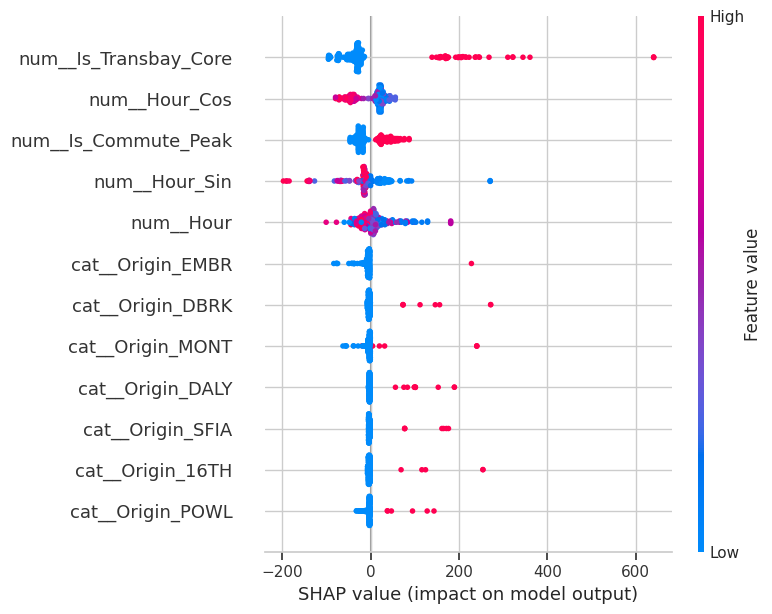

In [11]:
X_test_sample = X_test.sample(n=min(287, len(X_test)), random_state=42)
X_test_transformed = winner_pipeline.named_steps['prep'].transform(X_test_sample)
feature_names = winner_pipeline.named_steps['prep'].get_feature_names_out()

explainer = shap.TreeExplainer(winner_pipeline.named_steps['model'])
shap_values = explainer.shap_values(X_test_transformed)

plt.figure(figsize=(10, 6))
shap.summary_plot(shap_values, X_test_transformed, feature_names=feature_names, max_display=12, show=False)
plt.tight_layout()
plt.savefig("bart_shap_summary.png", dpi=150)
plt.show()